# 09 — Native multi-output ExtraTrees

**Group 119 — Henrik Remmen (541747)**  
**Kaggle team:** `[119] SINTEF Databreach`

This notebook uses one native multi-output ExtraTrees classifier to predict the 14 generator states for every case-hour row. A shared forest can choose splits that reduce impurity across several correlated units, while random split thresholds provide errors that differ from gradient boosting.

The implementation deliberately uses one 14-output forest per fold rather than 14 independent forests. This is faster, shares physical structure, and gives a genuinely different ensemble member.

> Saved unexecuted. You run all model cells yourself.


## 1. Setup and shared features

In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import ExtraTreesClassifier

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.sintef_pipeline import (
    HORIZON,
    RANDOM_SEED,
    build_project_data,
    make_submission,
    micro_auc,
    per_unit_auc,
    rows_for_cases,
)

sns.set_theme(style="whitegrid", context="notebook")
N_JOBS = 4
FEATURE_SET = "full_engineered"

print("Project root:", ROOT.resolve())


Project root: /Users/henrik/Documents/H26/Moderne Maksinlæring/sintef_project


In [2]:
# DATA/FEATURE CELL — no model training
data = build_project_data(ROOT)
FEATURES = data.feature_sets[FEATURE_SET]

print("Feature set:", FEATURE_SET)
print("Number of features:", len(FEATURES))
print("Feature matrix:", data.X_all.shape)
print("Outputs trained jointly:", len(data.units))


Feature set: full_engineered
Number of features: 175
Feature matrix: (612696, 175)
Outputs trained jointly: 14


## 2. Model and purged OOF evaluation

Large leaves and bounded depth smooth the forest probabilities and control memory. Class weighting is intentionally disabled because micro-AUC depends on comparable probability scales across units.

In [3]:
EXTRATREES_PARAMS = {
    "n_estimators": 350,
    "criterion": "log_loss",
    "max_depth": 24,
    "min_samples_split": 80,
    "min_samples_leaf": 40,
    "max_features": 0.50,
    "bootstrap": False,
    "n_jobs": N_JOBS,
    "random_state": RANDOM_SEED,
    "verbose": 0,
}

def make_extratrees(seed=RANDOM_SEED):
    params = dict(EXTRATREES_PARAMS)
    params["random_state"] = seed
    return ExtraTreesClassifier(**params)

def targets_by_case_hour(case_ids):
    return (
        data.target_cube[case_ids]
        .transpose(0, 2, 1)
        .reshape(-1, len(data.units))
    )

def positive_probability_matrix(model, X):
    probabilities = model.predict_proba(X)
    result = np.empty((len(X), len(data.units)), dtype=np.float32)

    for unit_index, (unit_probabilities, classes) in enumerate(
        zip(probabilities, model.classes_)
    ):
        positive = np.flatnonzero(np.asarray(classes) == 1)
        if len(positive) == 0:
            result[:, unit_index] = 0.0
        else:
            result[:, unit_index] = unit_probabilities[:, positive[0]]
    return result

def row_matrix_to_cube(matrix, n_cases):
    return (
        matrix.reshape(n_cases, HORIZON, len(data.units))
        .transpose(0, 2, 1)
    )

def evaluate_extratrees():
    oof = np.full(data.target_cube.shape, np.nan, dtype=np.float32)
    fold_rows = []
    unit_rows = []
    feature_importances = []

    for fold in data.folds:
        started = time.perf_counter()
        train_case_ids = fold["train_cases"]
        val_case_ids = fold["validation_cases"]
        train_rows = rows_for_cases(train_case_ids)
        val_rows = rows_for_cases(val_case_ids)
        X_train = data.X_all.loc[train_rows, FEATURES]
        X_val = data.X_all.loc[val_rows, FEATURES]
        y_train = targets_by_case_hour(train_case_ids)

        model = make_extratrees(RANDOM_SEED + fold["year"])
        model.fit(X_train, y_train)
        prediction_matrix = positive_probability_matrix(model, X_val)
        fold_prediction = row_matrix_to_cube(
            prediction_matrix,
            len(val_case_ids),
        )
        oof[val_case_ids] = fold_prediction
        feature_importances.append(model.feature_importances_)

        score = micro_auc(data.target_cube[val_case_ids], fold_prediction)
        elapsed = time.perf_counter() - started
        fold_rows.append({
            "validation_year": fold["year"],
            "micro_auc": score,
            "seconds": elapsed,
        })
        for unit, unit_score in per_unit_auc(
            data.target_cube[val_case_ids],
            fold_prediction,
            data.units,
        ).items():
            unit_rows.append({
                "validation_year": fold["year"],
                "unit": unit,
                "auc": unit_score,
            })
        print(
            f"Multi-output ExtraTrees | {fold['year']} | "
            f"micro AUC={score:.6f} | {elapsed:.1f}s"
        )

    return {
        "oof": oof,
        "fold_scores": pd.DataFrame(fold_rows),
        "unit_scores": pd.DataFrame(unit_rows),
        "feature_importances": np.vstack(feature_importances),
    }


In [4]:
# TRAINING CELL A — purged chronological OOF
extratrees_result = evaluate_extratrees()
extratrees_fold_scores = extratrees_result["fold_scores"]

display(extratrees_fold_scores.style.format({
    "micro_auc": "{:.6f}",
    "seconds": "{:.1f}",
}))
print("Mean AUC:", extratrees_fold_scores["micro_auc"].mean())
print("Worst-fold AUC:", extratrees_fold_scores["micro_auc"].min())

artifact_dir = ROOT / "artifacts" / "predictions"
artifact_dir.mkdir(parents=True, exist_ok=True)
np.savez_compressed(
    artifact_dir / "extratrees_multioutput_oof.npz",
    oof=extratrees_result["oof"],
)
extratrees_fold_scores.to_csv(
    artifact_dir / "extratrees_multioutput_fold_scores.csv",
    index=False,
)


Multi-output ExtraTrees | 2020 | micro AUC=0.816505 | 228.3s
Multi-output ExtraTrees | 2021 | micro AUC=0.908572 | 283.7s
Multi-output ExtraTrees | 2022 | micro AUC=0.940372 | 331.8s


,validation_year,micro_auc,seconds
0,2020,0.816505,228.3
1,2021,0.908572,283.7
2,2022,0.940372,331.8


Mean AUC: 0.8884831197462156
Worst-fold AUC: 0.8165049846525949


,feature,mean_importance,importance_std
84,price_margin__Vinjevatn,0.114850,0.005998
82,water_value_end__Vinjevatn,0.101391,0.008980
13,price_minus_water_value_mean,0.027821,0.004311
100,price_to_abs_water_value_ratio,0.022259,0.004530
169,margin_x_system_fill,0.020510,0.000947
66,price_margin__Botnedalsvatn,0.020188,0.000730
54,price_margin__Staavatn,0.018019,0.000749
81,price_margin__Songavatn,0.017376,0.001692
51,price_margin__Kjelavatn,0.016946,0.000422
69,price_margin__Bitdalsvatn,0.016274,0.001976


,mean,min
unit,,
Haukeli_G1,0.8230,0.7656
Lio_G1,0.8340,0.8021
Hogga_G1,0.8743,0.8409
Vinje_G3,0.9256,0.8793
Byrte_G1,0.9333,0.8680
Vinje_G2,0.9434,0.9154
Songa_G1,0.9468,0.8919
Vinje_G1,0.9486,0.9223
Vesle Kjela_G1,0.9522,0.8807


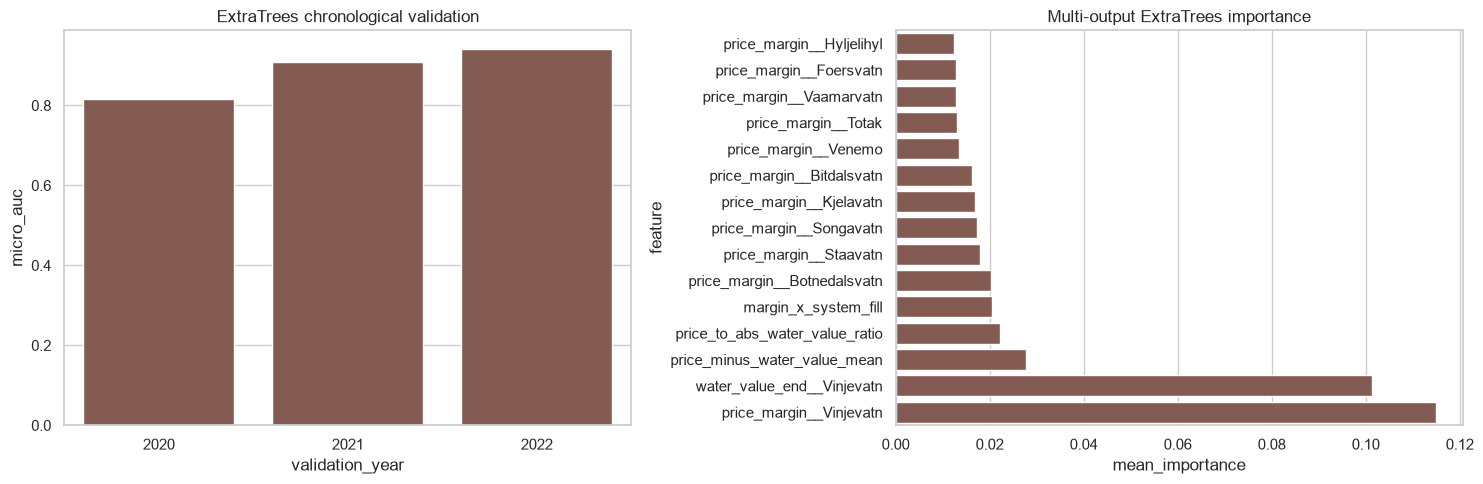

In [5]:
# FAST ANALYSIS CELL — no model fitting
importance = pd.DataFrame({
    "feature": FEATURES,
    "mean_importance": extratrees_result["feature_importances"].mean(axis=0),
    "importance_std": extratrees_result["feature_importances"].std(axis=0),
}).sort_values("mean_importance", ascending=False)
display(importance.head(25))

unit_summary = (
    extratrees_result["unit_scores"]
    .groupby("unit")["auc"]
    .agg(["mean", "min"])
    .sort_values("mean")
)
display(unit_summary.style.format("{:.4f}"))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(
    data=extratrees_fold_scores,
    x="validation_year",
    y="micro_auc",
    color="tab:brown",
    ax=axes[0],
)
axes[0].set(title="ExtraTrees chronological validation")
plot_importance = importance.head(15).sort_values("mean_importance")
sns.barplot(
    data=plot_importance,
    x="mean_importance",
    y="feature",
    color="tab:brown",
    ax=axes[1],
)
axes[1].set(title="Multi-output ExtraTrees importance")
plt.tight_layout()
plt.show()


## 3. Full-data forest and submission

In [6]:
# TRAINING CELL B — one final 14-output forest
train_rows = rows_for_cases(np.arange(data.n_train_cases))
test_rows = rows_for_cases(
    np.arange(data.n_train_cases, data.n_all_cases)
)
X_train_full = data.X_all.loc[train_rows, FEATURES]
X_test = data.X_all.loc[test_rows, FEATURES]
y_train_full = targets_by_case_hour(np.arange(data.n_train_cases))

final_model = make_extratrees(RANDOM_SEED)
final_model.fit(X_train_full, y_train_full)
test_matrix = positive_probability_matrix(final_model, X_test)
test_prediction = row_matrix_to_cube(test_matrix, data.n_test_cases)

submission_path, submission = make_submission(
    data,
    test_prediction,
    "extratrees_multioutput.csv",
)
print("Saved:", submission_path)
display(submission.iloc[:3, :8])


Saved: /Users/henrik/Documents/H26/Moderne Maksinlæring/sintef_project/submissions/extratrees_multioutput.csv


,Run No,result_committed_Hogga_G1_t0,result_committed_Hogga_G1_t1,result_committed_Hogga_G1_t2,result_committed_Hogga_G1_t3,result_committed_Hogga_G1_t4,result_committed_Hogga_G1_t5,result_committed_Hogga_G1_t6
0,2923,0.198360,0.167047,0.095931,0.077086,0.065133,0.063364,0.045433
1,2924,0.592813,0.580183,0.574805,0.609767,0.566833,0.637393,0.885092
2,2925,0.655381,0.631435,0.556597,0.542905,0.706912,0.849624,0.921380


### Kaggle description

`Multi-output ExtraTrees – shared 14-unit forest and full engineered features`

Its main purpose is diversity. Do not promote it solely because it is a different algorithm; require competitive OOF score or a measurable ensemble gain.
